# Anatomical dependence: does coupling just track recording proximity?

Extended to **every OF1 session with usable pairwise-assay data**
(`>= MIN_FILES` cached CSV batches, discovered automatically from
`data/eddie/xgboost_pairwise/`), not just the three sessions used in the
rest of this investigation -- the anatomical confound is a property of the
recording/method, not of any one session, so it needs checking broadly.

Rule used per session: **multishank recordings are sorted by
medial-lateral (ML) position** (`SC_x`); **single-shank recordings are
sorted by dorsal-ventral (DV) position** (`SC_y`) -- the only axis with
real spread within one shank. Determined per session directly from
`shank_id` in `cell_classifications.csv`.

Two checks per session: (1) the matrix reordered by that anatomical axis;
(2) a pairwise anatomical-distance (3D `SC_x,SC_y,SC_z`) vs. coupling
relationship, Spearman correlation with significance from a Mantel-style
permutation test (position labels shuffled relative to the fixed coupling
matrix, since pairwise distances aren't independent observations).

With ~45 sessions, individual sorted-matrix figures are saved to disk for
every session but only the largest-effect examples are shown inline; the
main inline output is the population summary across all sessions.

In [1]:
import numpy as np
import pandas as pd
import glob
import os
import re
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams['font.family'] = 'Arial'

DATA_PATH = '/Users/harryclark/Documents/spatial-manifolds/data/eddie/xgboost_pairwise/'
CC_PATH   = '/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications.csv'
FIG_PATH  = '/Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/anatomical_dependence/'
os.makedirs(FIG_PATH, exist_ok=True)

HISTORY_LENGTH = 100
SESSION_TYPE   = 'OF1'
MIN_FILES      = 5     # minimum cached pairwise-CSV batches to include a session (~40+ cells)
RICH_BASELINE  = {'VR': 'pos_speed_lfp', 'OF1': 'pos_speed_hd_hing_lfp'}
RAW_BASELINE   = 'null'
N_PERM         = 1000
RNG_SEED       = 42


def discover_sessions(session_type=SESSION_TYPE, min_files=MIN_FILES):
    files = glob.glob(os.path.join(DATA_PATH, f'xgboost_pairwise_M*_D*_h{HISTORY_LENGTH}_{session_type}_*.csv'))
    counts = {}
    for f in files:
        m = re.search(rf'xgboost_pairwise_M(\d+)_D(\d+)_h{HISTORY_LENGTH}_{session_type}_', os.path.basename(f))
        if m:
            key = (int(m.group(1)), int(m.group(2)))
            counts[key] = counts.get(key, 0) + 1
    return sorted(k for k, v in counts.items() if v >= min_files)


SESSIONS = discover_sessions()
print(f'{len(SESSIONS)} {SESSION_TYPE} sessions with >= {MIN_FILES} pairwise files:')
print(SESSIONS)

45 OF1 sessions with >= 5 pairwise files:
[(20, 14), (20, 15), (20, 16), (20, 17), (20, 18), (20, 19), (20, 20), (20, 21), (20, 22), (20, 23), (20, 24), (20, 26), (21, 15), (21, 16), (21, 17), (21, 18), (21, 19), (21, 20), (21, 21), (21, 22), (21, 23), (21, 24), (21, 25), (21, 26), (22, 33), (22, 35), (22, 36), (22, 37), (22, 38), (25, 17), (25, 18), (25, 19), (25, 20), (25, 21), (25, 22), (25, 23), (25, 24), (25, 25), (26, 11), (26, 12), (26, 13), (26, 15), (26, 18), (26, 19), (29, 25)]


## 1. Load anatomical coordinates + pairwise results, build matrices

In [2]:
cc = pd.read_csv(CC_PATH, low_memory=False)
cc['mouse']      = cc['mouse'].astype(int)
cc['day']        = cc['day'].astype(int)
cc['cluster_id'] = cc['cluster_id'].astype(int)


def get_anatomy(mouse, day):
    sub = cc[(cc.mouse == mouse) & (cc.day == day)].drop_duplicates('cluster_id')
    n_shanks = sub['shank_id'].nunique(dropna=True)
    sort_axis = 'SC_x' if n_shanks > 1 else 'SC_y'
    axis_name = 'ML' if n_shanks > 1 else 'DV'
    coords = sub.set_index('cluster_id')[['SC_x', 'SC_y', 'SC_z', 'shank_id', 'cell_type']]
    return coords, sort_axis, axis_name, int(n_shanks)


def load_pairwise(mouse, day, session_type):
    pattern = os.path.join(DATA_PATH, f'xgboost_pairwise_M{mouse}_D{day}_h{HISTORY_LENGTH}_{session_type}_*.csv')
    files = sorted(glob.glob(pattern))
    if not files:
        return None
    return pd.concat([pd.read_csv(f, keep_default_na=False) for f in files], ignore_index=True)


def build_pr2_matrix(pw_df, baseline):
    bl = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id == -1)]
          [['target_cluster_id', 'pR2_cv']].rename(columns={'pR2_cv': 'pR2_baseline'})
          .drop_duplicates('target_cluster_id'))
    cv = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id >= 0)]
          [['target_cluster_id', 'covariate_cluster_id', 'pR2_cv']].copy())
    merged = cv.merge(bl, on='target_cluster_id', how='inner')
    merged['d'] = merged['pR2_cv'] - merged['pR2_baseline']
    all_ids = sorted(set(merged.target_cluster_id) | set(merged.covariate_cluster_id))
    idx = {cid: i for i, cid in enumerate(all_ids)}
    N = len(all_ids)
    mat = np.full((N, N), np.nan)
    for row in merged.itertuples(index=False):
        mat[idx[int(row.covariate_cluster_id)], idx[int(row.target_cluster_id)]] = row.d
    np.fill_diagonal(mat, 0)
    sym = np.nan_to_num(np.nanmean(np.stack([mat, mat.T]), axis=0), nan=0.0)
    return sym, all_ids


def build_session_matrices(pw_df, session_type):
    raw_sym, ids_raw = build_pr2_matrix(pw_df, RAW_BASELINE)
    delta_sym, ids_delta = build_pr2_matrix(pw_df, RICH_BASELINE[session_type])
    assert ids_raw == ids_delta
    return dict(raw=raw_sym, delta=delta_sym), ids_raw

## 2. Mantel test: pairwise anatomical distance vs. coupling, every session

Run first (before the sorted-matrix plots) so the plotting step can save
every session to disk without flooding this notebook's output, and only
display the largest-effect examples inline afterwards.

In [3]:
def mantel_distance_test(mouse, day, session_type, metric, n_perm=N_PERM, seed=RNG_SEED):
    coords, sort_axis, axis_name, n_shanks = get_anatomy(mouse, day)
    pw = load_pairwise(mouse, day, session_type)
    if pw is None:
        return None
    mats, cell_ids = build_session_matrices(pw, session_type)

    have_coord = [cid for cid in cell_ids if cid in coords.index and
                 coords.loc[cid, ['SC_x', 'SC_y', 'SC_z']].notna().all()]
    if len(have_coord) < 10:
        return None
    idx_map = {cid: i for i, cid in enumerate(cell_ids)}
    rows = [idx_map[cid] for cid in have_coord]
    sub_mat = mats[metric][np.ix_(rows, rows)]
    xyz = coords.loc[have_coord, ['SC_x', 'SC_y', 'SC_z']].values.astype(float)

    n = len(have_coord)
    iu = np.triu_indices(n, k=1)

    def dist_vec(coords_arr):
        d = coords_arr[:, None, :] - coords_arr[None, :, :]
        return np.sqrt((d ** 2).sum(axis=2))[iu]

    dvec = dist_vec(xyz)
    cvec = sub_mat[iu]
    rho_obs, _ = spearmanr(dvec, cvec)

    rng = np.random.default_rng(seed)
    null_rho = np.empty(n_perm)
    for k in range(n_perm):
        perm = rng.permutation(n)
        null_rho[k] = spearmanr(dist_vec(xyz[perm]), cvec)[0]

    p = (np.sum(np.abs(null_rho) >= np.abs(rho_obs)) + 1) / (n_perm + 1)
    return dict(n=n, rho=rho_obs, p=p, dvec=dvec, cvec=cvec, null_rho=null_rho,
               sort_axis=sort_axis, axis_name=axis_name, n_shanks=n_shanks)


anatomy_results = {}
summary_rows = []
for i, (mouse, day) in enumerate(SESSIONS):
    for metric in ('raw', 'delta'):
        res = mantel_distance_test(mouse, day, SESSION_TYPE, metric=metric)
        if res is None:
            continue
        anatomy_results[(mouse, day, SESSION_TYPE, metric)] = res
        summary_rows.append(dict(mouse=mouse, day=day, metric=metric, n=res['n'],
                                 axis=res['axis_name'], n_shanks=res['n_shanks'],
                                 rho=res['rho'], p=res['p']))
    print(f'[{i+1}/{len(SESSIONS)}] M{mouse} D{day} done', end='\r')

anatomy_summary = pd.DataFrame(summary_rows)
anatomy_summary.to_csv(os.path.join(FIG_PATH, 'anatomy_summary_all_sessions.csv'), index=False)
print(f'\ndone: {len(anatomy_summary)} session x metric results')

[45/45] M29 D25 done
done: 90 session x metric results


## 3. Population summary across all OF1 sessions

[raw] 37/45 sessions significant (p<0.05), median rho=-0.1531, mean rho=-0.1626, 98% negative (closer = more coupled)
[delta] 34/45 sessions significant (p<0.05), median rho=-0.1378, mean rho=-0.1391, 98% negative (closer = more coupled)


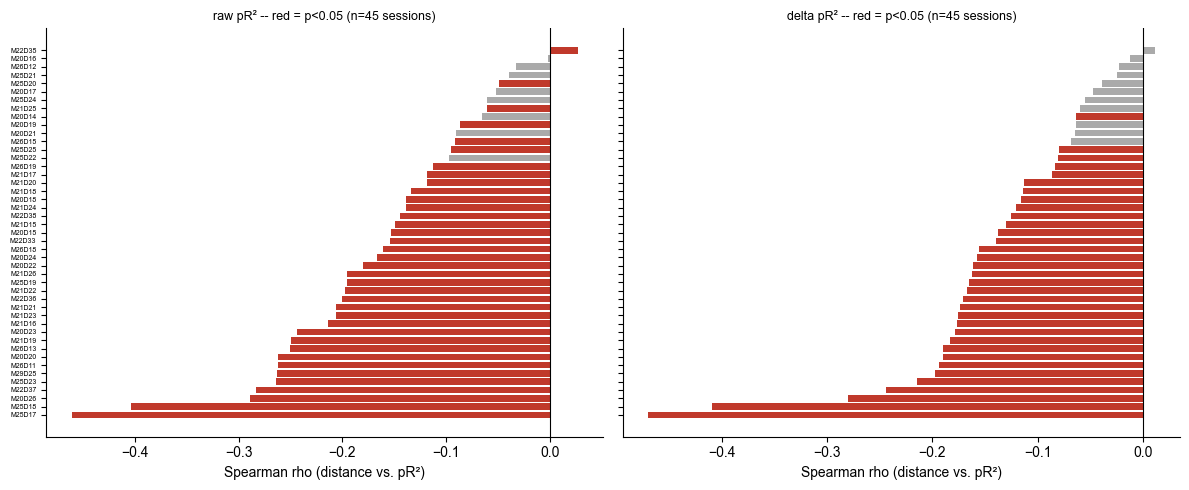

In [4]:
for metric in ('raw', 'delta'):
    sub = anatomy_summary[anatomy_summary.metric == metric]
    n_sig = (sub.p < 0.05).sum()
    print(f'[{metric}] {n_sig}/{len(sub)} sessions significant (p<0.05), '
         f'median rho={sub.rho.median():.4f}, mean rho={sub.rho.mean():.4f}, '
         f'{(sub.rho < 0).mean()*100:.0f}% negative (closer = more coupled)')

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric in zip(axes, ('raw', 'delta')):
    sub = anatomy_summary[anatomy_summary.metric == metric].sort_values('rho').reset_index(drop=True)
    colors = np.where(sub.p < 0.05, '#c0392b', '#aaaaaa')
    ax.barh(range(len(sub)), sub.rho, color=colors, height=0.8)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels([f'M{m}D{d}' for m, d in zip(sub.mouse, sub.day)], fontsize=5)
    ax.set_xlabel('Spearman rho (distance vs. pR²)')
    ax.set_title(f'{metric} pR² -- red = p<0.05 (n={len(sub)} sessions)', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, 'population_rho_forest.pdf'), dpi=200, bbox_inches='tight')
plt.show()

## 4. Sorted-matrix figure for every session (saved to disk; not displayed inline for all ~45)

In [5]:
def plot_anatomy_sorted(mouse, day, session_type):
    coords, sort_axis, axis_name, n_shanks = get_anatomy(mouse, day)
    pw = load_pairwise(mouse, day, session_type)
    if pw is None:
        return None
    mats, cell_ids = build_session_matrices(pw, session_type)

    have_coord = [cid for cid in cell_ids if cid in coords.index and pd.notna(coords.loc[cid, sort_axis])]
    missing = len(cell_ids) - len(have_coord)
    order_vals = coords.loc[have_coord, sort_axis].values
    order = np.argsort(order_vals)
    ordered_ids = [have_coord[i] for i in order]
    idx_map = {cid: i for i, cid in enumerate(cell_ids)}
    mat_idx = [idx_map[cid] for cid in ordered_ids]

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
    for ax, metric in zip(axes, ['raw', 'delta']):
        m = mats[metric][np.ix_(mat_idx, mat_idx)]
        vmax = np.nanpercentile(np.abs(m), 98) if np.any(m != 0) else 1.0
        im = ax.imshow(m, cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest', aspect='auto')
        plt.colorbar(im, ax=ax, fraction=0.045, pad=0.02).set_label(f'{metric} pR²', fontsize=7)
        n_ticks = 6
        tick_idx = np.linspace(0, len(ordered_ids) - 1, n_ticks).astype(int)
        ax.set_yticks(tick_idx)
        ax.set_yticklabels([f'{order_vals[order][i]:.0f}' for i in tick_idx], fontsize=7)
        ax.set_xticks([])
        ax.set_title(f'{metric} pR², sorted by {axis_name} ({sort_axis})', fontsize=9)
    axes[0].set_ylabel(f'{axis_name} position (µm)')
    fig.suptitle(f'M{mouse} D{day} {session_type}  (n_shanks={n_shanks}, missing coords={missing})',
                fontsize=11, fontweight='bold')
    plt.tight_layout()
    return fig


for i, (mouse, day) in enumerate(SESSIONS):
    fig = plot_anatomy_sorted(mouse, day, SESSION_TYPE)
    if fig is not None:
        fig.savefig(os.path.join(FIG_PATH, f'anatomy_sorted_M{mouse}D{day}_{SESSION_TYPE}.pdf'),
                   dpi=200, bbox_inches='tight')
        plt.close(fig)
    print(f'[{i+1}/{len(SESSIONS)}] saved M{mouse} D{day}', end='\r')
print(f'\nsaved {len(SESSIONS)} sorted-matrix figures to {FIG_PATH}')

[45/45] saved M29 D25
saved 45 sorted-matrix figures to /Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/anatomical_dependence/


## 5. Inline highlights: the largest-effect sessions (Δ pR²)

 mouse  day   n axis       rho        p
    25   17  50   ML -0.469841 0.000999
    25   18 135   ML -0.409161 0.000999
    20   26 146   DV -0.280423 0.000999
    22   37  87   ML -0.244265 0.000999
    25   23 182   DV -0.214893 0.000999
    29   25 202   ML -0.197795 0.000999


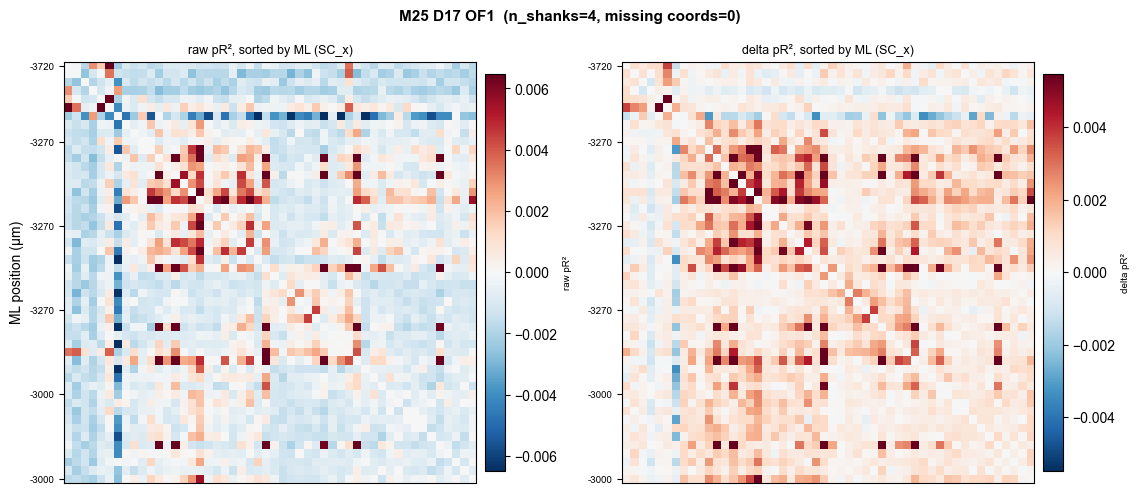

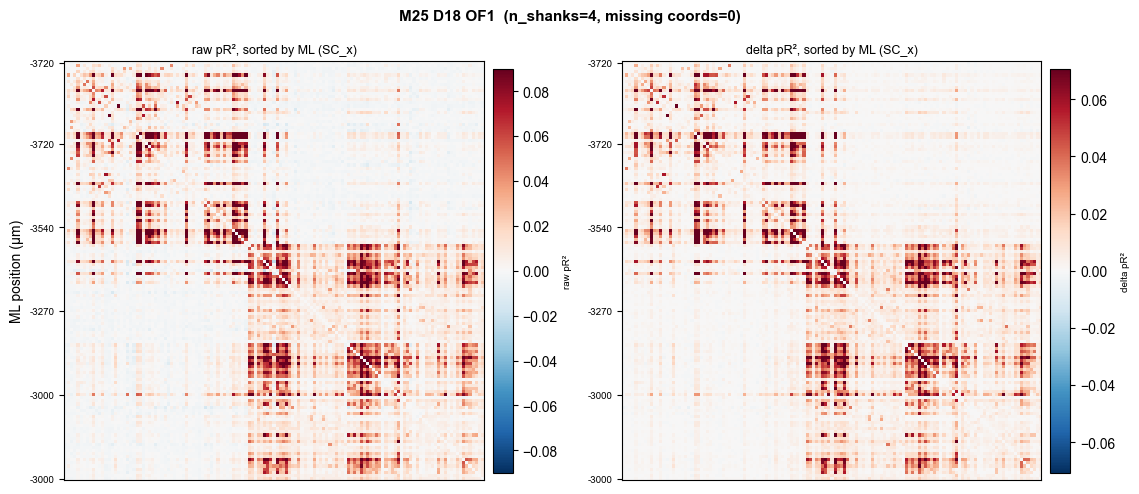

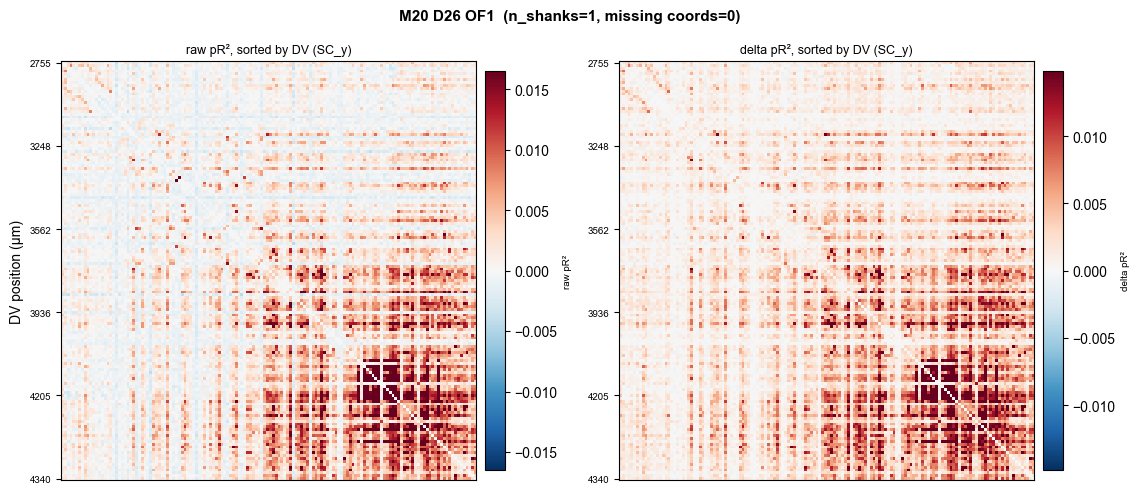

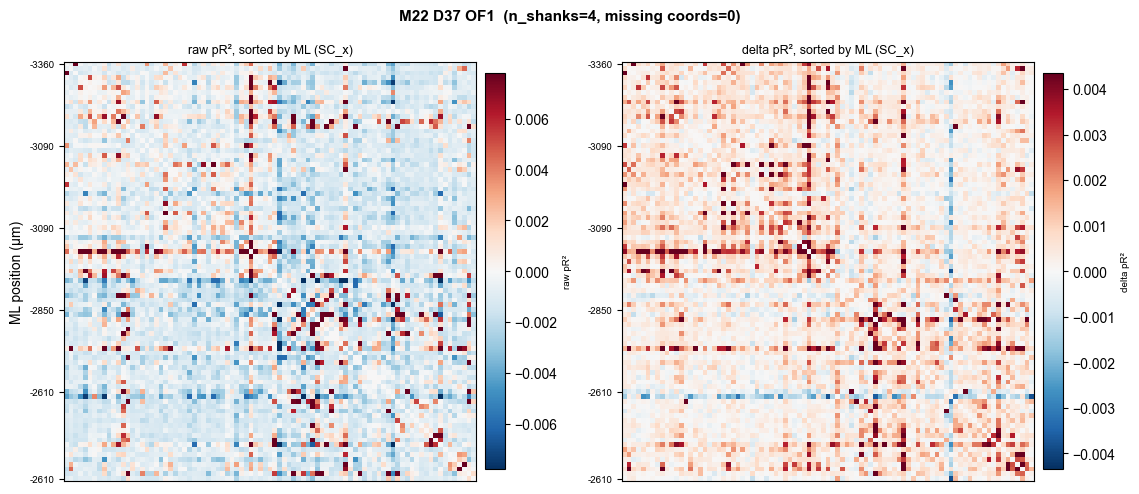

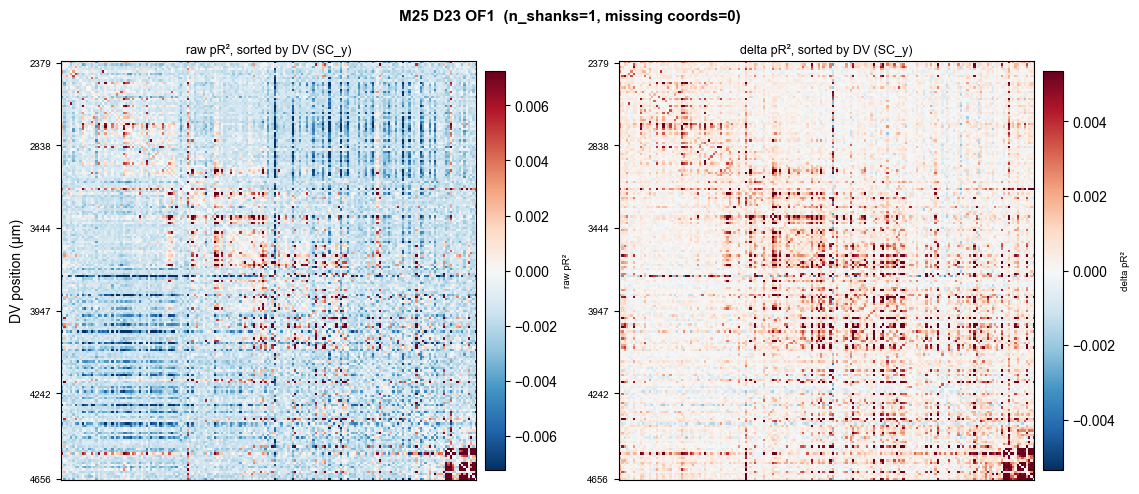

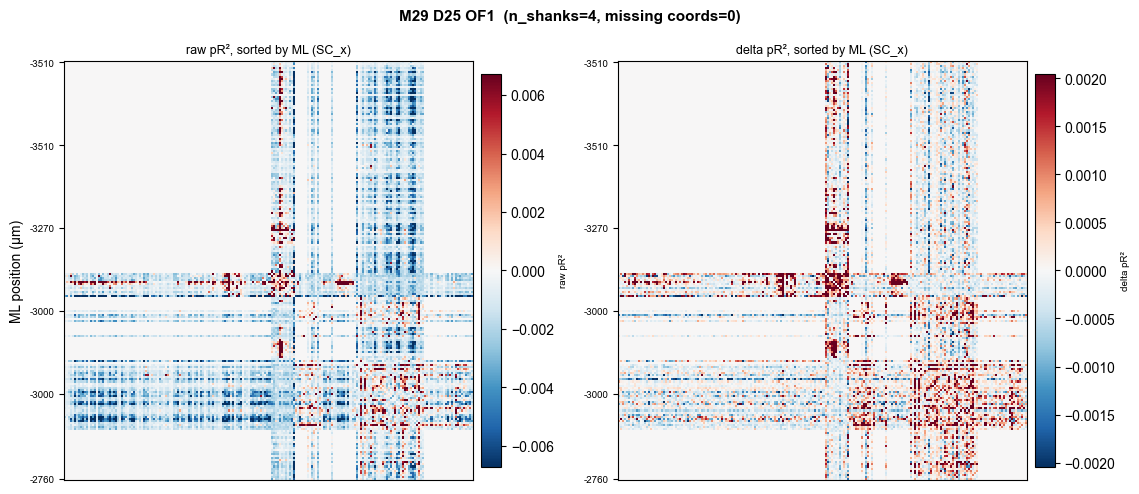

In [6]:
top = (anatomy_summary[anatomy_summary.metric == 'delta']
      .assign(abs_rho=lambda d: d.rho.abs())
      .sort_values('abs_rho', ascending=False)
      .head(6))
print(top[['mouse', 'day', 'n', 'axis', 'rho', 'p']].to_string(index=False))

for _, row in top.iterrows():
    fig = plot_anatomy_sorted(int(row.mouse), int(row.day), SESSION_TYPE)
    if fig is not None:
        plt.show()

## 6. Distance-vs-coupling scatter for the same highlighted sessions

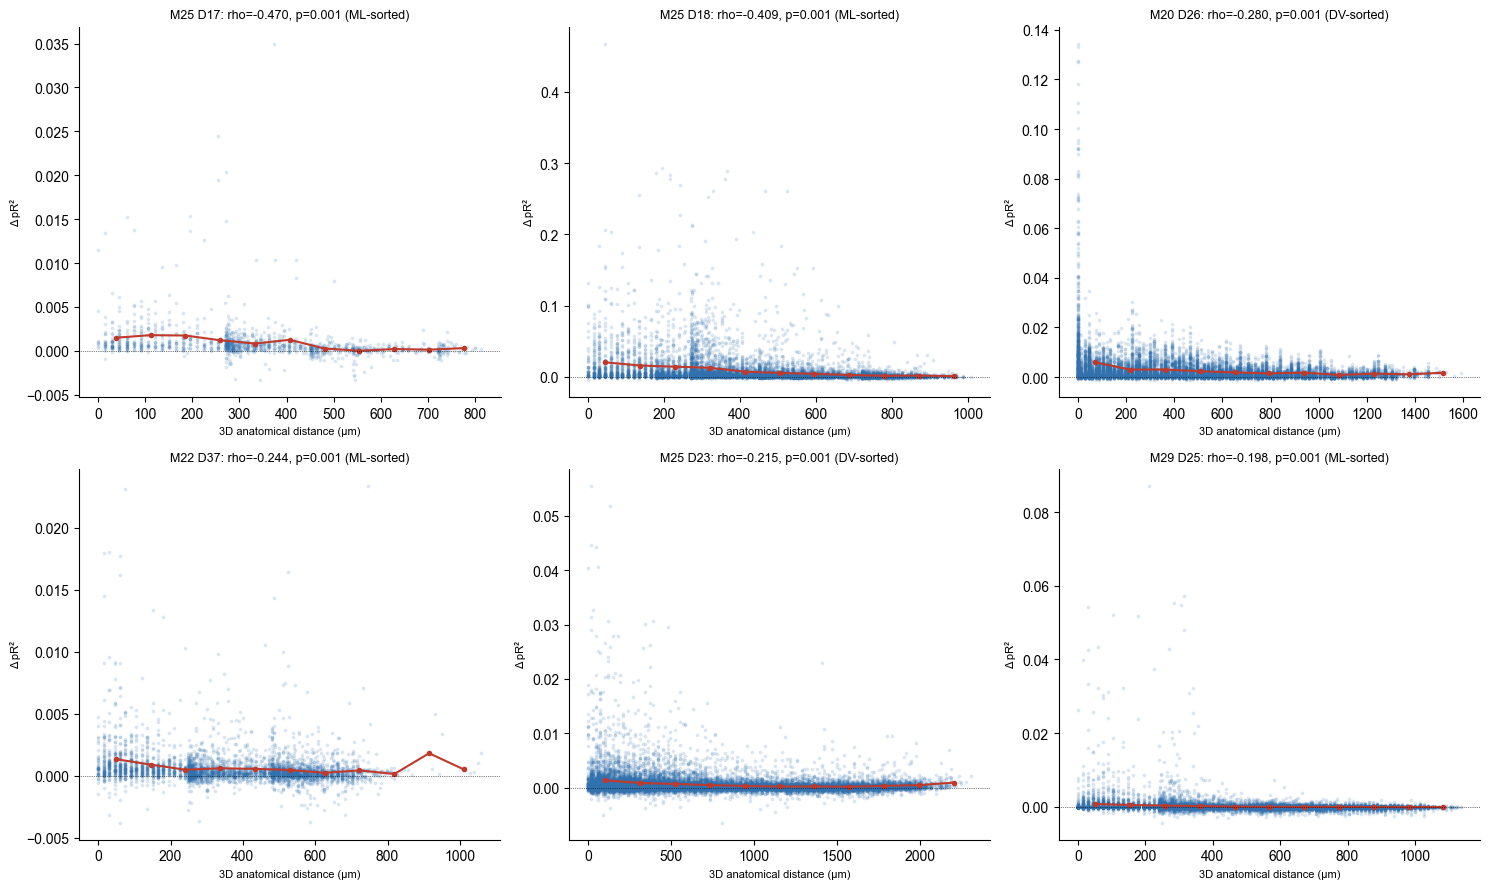

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (_, row) in zip(axes.flat, top.iterrows()):
    mouse, day = int(row.mouse), int(row.day)
    res = anatomy_results.get((mouse, day, SESSION_TYPE, 'delta'))
    if res is None:
        continue
    ax.scatter(res['dvec'], res['cvec'], s=3, alpha=0.12, color='#3171ae')
    bins = np.linspace(res['dvec'].min(), res['dvec'].max(), 12)
    bin_idx = np.digitize(res['dvec'], bins)
    bin_means = [res['cvec'][bin_idx == b].mean() for b in range(1, len(bins))]
    bin_centers = (bins[:-1] + bins[1:]) / 2
    ax.plot(bin_centers, bin_means, color='#c0392b', lw=1.5, marker='o', ms=3)
    ax.axhline(0, color='k', lw=0.5, ls=':')
    ax.set_xlabel('3D anatomical distance (µm)', fontsize=8)
    ax.set_ylabel('Δ pR²', fontsize=8)
    ax.set_title(f'M{mouse} D{day}: rho={res["rho"]:.3f}, p={res["p"]:.3f} ({res["axis_name"]}-sorted)',
                fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_PATH, 'distance_vs_coupling_scatter_top6.pdf'), dpi=200, bbox_inches='tight')
plt.show()